In [1]:
!poetry install -q

In [2]:
%load_ext autoreload
%autoreload 2

import os
import sys
import datetime
import numpy as np
import pandas as pd
from dotenv import load_dotenv

# OpenMP 다중 로드 허용 및 스레드 경쟁 방지 환경 변수 (최상단 주입 필수)
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

# 1. 프로젝트 경로 설정 및 환경 변수 명시적 로드
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

# Docker 네트워크 외부(Host OS)에서 실행되는 Jupyter를 위한 DNS 해석 우회 처리
local_s3_endpoint = os.environ.get("LOCAL_S3_ENDPOINT", "")
if "localstack" in local_s3_endpoint:
    os.environ["LOCAL_S3_ENDPOINT"] = local_s3_endpoint.replace("localstack", "localhost")

In [3]:
# DataFrame 출력 생략 방지 옵션 설정
pd.set_option('display.max_columns', None)        # 숨김 없이 모든 컬럼 출력
pd.set_option('display.max_colwidth', None)       # 컬럼 안의 긴 텍스트(Dict/List) 전체 출력
pd.set_option('display.expand_frame_repr', False) # 가로 너비 초과 시 줄바꿈 방지
pd.set_option('display.max_rows', 50)             # 필요시 최대 출력 행 수 조정

In [4]:
from pathlib import Path
from typing import Any, Dict, Optional
import pandas as pd

from src.model.deployment.single_model_loader import (
    LoadedChampionArtifacts,
    load_single_model,
)

# ==============================================================================
# 0. 챔피언 아티팩트 일괄 로드 (출력 억제 및 무결성 컨테이너 획득)
# ==============================================================================
# [설계 의도] 후속 분석 노트북 환경의 콘솔/테이블 출력 오염을 방지하기 위해 auto_display=False를 명시적으로 주입
loaded_artifacts: LoadedChampionArtifacts = load_single_model(artifact_root="artifacts", auto_display=False)

# ==============================================================================
# 1. 모델 영속화 계층 (Model & Metadata)
# ==============================================================================
# [설계 의도] 챔피언 회귀 추정기 인스턴스 및 5대 게이트 평가 지표·하이퍼파라미터 메타데이터 바인딩
champion_model: Any = loaded_artifacts.model
champion_metadata: Dict[str, Any] = loaded_artifacts.metadata

# ==============================================================================
# 2. XAI 수리통계 데이터 계층 (Explainable AI & Audit Artifacts)
# ==============================================================================
# [설계 의도] OOS 테스트셋에 대한 원시 SHAP 기여도 행렬, 표준 중요도 감사표 및 공리 검정 메타데이터 바인딩
shap_values_test: pd.DataFrame = loaded_artifacts.shap_values
feature_importance_report: pd.DataFrame = loaded_artifacts.feature_importance_report
xai_summary: Dict[str, Any] = loaded_artifacts.xai_summary

# [설계 의도] 직전 단계에서 신규 영속화된 리스크 변곡점 컷오프 정책표 및 5대 시장 국면 정량 감사표 바인딩
inflection_policy_summary: Optional[pd.DataFrame] = loaded_artifacts.inflection_policy_summary
regime_cohort_audit: Optional[pd.DataFrame] = loaded_artifacts.regime_cohort_audit

# ==============================================================================
# 3. 백테스팅 전략 인계 계층 (Data Contract & Inference)
# ==============================================================================
# [설계 의도] 시간 순서 및 DatetimeIndex가 보존된 테스트셋 피처-타깃 행렬 및 모델 예측값/잔차 벡터 계약 바인딩
test_features_and_target: pd.DataFrame = loaded_artifacts.test_features_and_target
test_predictions: pd.DataFrame = loaded_artifacts.test_predictions

# ==============================================================================
# 4. 아티팩트 물리 경로 매핑 (Artifact File Paths)
# ==============================================================================
# [설계 의도] 디스크 상의 모든 모델, 평가 플롯, XAI 시각화/데이터 파일의 물리 경로 매핑 바인딩
artifact_paths: Dict[str, Path] = loaded_artifacts.artifact_paths

In [5]:
# ==============================================================================
# [셀 1] XAI 리스크 거버넌스 정책 빌드 및 3대 감사 대시보드 사출
# ==============================================================================
import pandas as pd
from src.test.backtest.risk_governance import (
    build_xai_risk_governance_report,
    generate_xai_risk_governance_gates,
)

# 1. XAI 거버넌스 실행 설정 및 3대 감사 대시보드 테이블 동적 생성
governance_config, dashboards = build_xai_risk_governance_report(
    feature_importance_report=feature_importance_report,
    inflection_policy_summary=inflection_policy_summary,
    features=test_features_and_target,
)

# 2. 백테스팅 엔진 주입용 시계열 게이트 연산 획득
target_features: list[str] = list(governance_config["feature_weights"].keys())
composite_risk_gate, individual_gates, risk_distances = generate_xai_risk_governance_gates(
    features=test_features_and_target[target_features],
    risk_policy_configuration=governance_config,
)

# ------------------------------------------------------------------------------
# 3. 확정 대시보드 출력 (1. 완성된 리스크 게이트 + 리스크 게이트 정보)
# ------------------------------------------------------------------------------
print("=" * 120)
print("[XAI-Gated Decision Governance] 3단계 위험 통제 파이프라인 실행 및 감사 대시보드")
print("=" * 120)
print("▶ 파이프라인 수행 단계 및 역할 정의:")
print("  • Step 1 [위험 침범 거리 산출]: 8대 팩터 관측치가 학습 변곡점(θ)을 벗어난 표준화 거리(z) 측정 (z<=0 정상, z>0 위험)")
print("  • Step 2 [비선형 시그모이드 감쇠]: 침범 거리(z)를 매끄러운 알파 생존 계수(g ∈ (0, 1])로 변환하여 절벽 효과 방지")
print("  • Step 3 [XAI 가중 복합 결합]: 글로벌 SHAP 중요도(w)로 기하 결합하여 시장 전체의 단일 종합 생존율(G_t) 도출")

print("\n" + "=" * 120)
print("1. [Step 3 결과] 완성된 종합 리스크 게이트(G_t) 및 국면별 팩터 영향도 분해 대시보드")
print("=" * 120)
print("[핵심 역할] 거시 시장 위험을 0.0 ~ 1.0의 단일 생존율로 집약하고, 디리스킹 발동 시 어떤 팩터가 주원인이었는지 규명합니다.\n")

print("[1-1] 종합 리스크 게이트(G_t) 통계 및 3대 운용 국면 분포 요약")
print("-" * 120)
display(dashboards["gate_summary"])

print("\n[1-2] 거버넌스 운용 국면별 8대 팩터 영향도 및 위험 유발 기여도 분해")
print("-" * 120)
display(dashboards["regime_attribution"])

# ------------------------------------------------------------------------------
# 4. 확정 대시보드 출력 (2. 각 게이트 정보)
# ------------------------------------------------------------------------------
print("\n" + "=" * 120)
print("2. [Step 1 & Step 2 결과] 8대 팩터별 세부 게이트 감사 및 수리 상태 추적표 (Audit Trail)")
print("=" * 120)
print("[핵심 역할] 팩터별 사전 동결 모수(θ, σ, s, w)와 실측 침범 거리(z), 개별 감쇠 계수(g)의 1:1 대응 관계를 전수 검증합니다.\n")
display(dashboards["factor_audit_trail"])

[XAI-Gated Decision Governance] 3단계 위험 통제 파이프라인 실행 및 감사 대시보드
▶ 파이프라인 수행 단계 및 역할 정의:
  • Step 1 [위험 침범 거리 산출]: 8대 팩터 관측치가 학습 변곡점(θ)을 벗어난 표준화 거리(z) 측정 (z<=0 정상, z>0 위험)
  • Step 2 [비선형 시그모이드 감쇠]: 침범 거리(z)를 매끄러운 알파 생존 계수(g ∈ (0, 1])로 변환하여 절벽 효과 방지
  • Step 3 [XAI 가중 복합 결합]: 글로벌 SHAP 중요도(w)로 기하 결합하여 시장 전체의 단일 종합 생존율(G_t) 도출

1. [Step 3 결과] 완성된 종합 리스크 게이트(G_t) 및 국면별 팩터 영향도 분해 대시보드
[핵심 역할] 거시 시장 위험을 0.0 ~ 1.0의 단일 생존율로 집약하고, 디리스킹 발동 시 어떤 팩터가 주원인이었는지 규명합니다.

[1-1] 종합 리스크 게이트(G_t) 통계 및 3대 운용 국면 분포 요약
------------------------------------------------------------------------------------------------------------------------


,평균 생존율(Mean),표준편차(Std),최소 생존율(Min),[국면 1] 정상 운용,[국면 2] 경미 감쇠,[국면 3] 고위험 억제
지표 구분,,,,,,
기준 범위,-,-,-,(G >= 0.99),(0.80 <= G < 0.99),(G < 0.80)
G_t 시계열 통계,0.7900,0.1446,0.3412,3.14%,50.69%,46.17%



[1-2] 거버넌스 운용 국면별 8대 팩터 영향도 및 위험 유발 기여도 분해
------------------------------------------------------------------------------------------------------------------------


,글로벌 XAI 중요도 비중(w),[국면 1] 정상 운용 평균 생존율(g),[국면 2] 경미 감쇠 평균 생존율(g),[국면 3] 고위험 억제 평균 생존율(g),전체 디리스킹 위험 기여율(%)
팩터 명칭 (Feature Name),,,,,
kis_kospi_construction_rolling_kurt_20d,21.3%,1.0000,0.8772,0.7226,21.2%
kis_global_france_cac40_norm_atr_20d,18.8%,0.9981,0.9653,0.7531,14.1%
kis_kosdaq_finance_norm_atr_20d,18.5%,0.9937,0.8296,0.3923,45.4%
kis_global_europe_stoxx50_return_lag_60d,12.9%,1.0000,0.8996,0.8815,7.1%
kis_global_france_cac40_volatility_20d,12.3%,0.9996,0.9719,0.8513,5.5%
kis_kosdaq_pharmaceutical_norm_atr_20d,9.9%,1.0000,0.9662,0.9208,2.6%
kis_kosdaq_non_metallic_rolling_kurt_20d,3.2%,0.9836,0.8714,0.9415,1.6%
kis_kosdaq_food_beverage_norm_atr_20d,3.1%,0.9887,0.9216,0.7683,2.6%
합계 (Total / Weighted Attribution),100.0%,0.9975,0.9096,0.7315,100.0%



2. [Step 1 & Step 2 결과] 8대 팩터별 세부 게이트 감사 및 수리 상태 추적표 (Audit Trail)
[핵심 역할] 팩터별 사전 동결 모수(θ, σ, s, w)와 실측 침범 거리(z), 개별 감쇠 계수(g)의 1:1 대응 관계를 전수 검증합니다.



,기준치(θ),학습표준편차(σ),방향(s),가중치(w),평균거리,최대침범,위험진입률,평균생존율,최저생존율,감쇠발동률
팩터 명칭 (Feature Name),,,,,,,,,,
kis_kospi_construction_rolling_kurt_20d,0.1088,1.1719,하회(-1),21.3%,0.0208,2.3551,57.8%,0.8097,0.1733,57.6%
kis_global_france_cac40_norm_atr_20d,0.5414,1.3955,초과(+1),18.8%,-0.3284,1.7618,34.4%,0.8683,0.2931,34.0%
kis_kosdaq_finance_norm_atr_20d,-0.8313,1.2744,초과(+1),18.5%,0.8075,3.0062,78.2%,0.6328,0.0943,77.6%
kis_global_europe_stoxx50_return_lag_60d,-0.6996,1.2992,하회(-1),12.9%,-0.4351,1.7706,35.2%,0.8944,0.2909,34.2%
kis_global_france_cac40_volatility_20d,0.9400,1.3028,초과(+1),12.3%,-0.6664,1.5812,25.3%,0.9171,0.3413,25.1%
kis_kosdaq_pharmaceutical_norm_atr_20d,1.1294,1.2574,초과(+1),9.9%,-0.7946,1.3940,24.6%,0.9463,0.3975,23.8%
kis_kosdaq_non_metallic_rolling_kurt_20d,0.5000,1.0722,초과(+1),3.2%,-0.5008,2.3317,33.0%,0.9073,0.1771,31.6%
kis_kosdaq_food_beverage_norm_atr_20d,0.5000,1.3570,초과(+1),3.1%,-0.2200,1.7852,37.3%,0.8529,0.2873,36.5%


In [6]:
# [셀 2] 변동성 연동 동적 불감대 산출 및 3-Action 신호 확정
from src.test.backtest.execution_strategy import generate_ablation_execution_signals

signals_raw_model, signals_xai_gated, action_summary_table = (
    generate_ablation_execution_signals(
        raw_predictions=test_predictions["prediction"],
        composite_gating_scores=composite_risk_gate,
    )
)

display(action_summary_table)

,Strategy 1 (Raw Model),Strategy 2 (XAI-Gated)
Execution Governance Audit,,
Total Horizon (Days),509 영업일,509 영업일
BUY Action Count (%),12회 (2.4%),13회 (2.6%)
HOLD Action Count (%),486회 (95.5%),484회 (95.1%)
├─ Hold in Long Position,225일 (44.2%),177일 (34.8%)
└─ Hold in Cash (Flat),261일 (51.3%),307일 (60.3%)
SELL Action Count (%),11회 (2.2%),12회 (2.4%)
Market Exposure Ratio (%),46.6%,37.3%
Completed Trades (Count),11회,12회
Mean Holding Period (Days),21.5 영업일,15.8 영업일


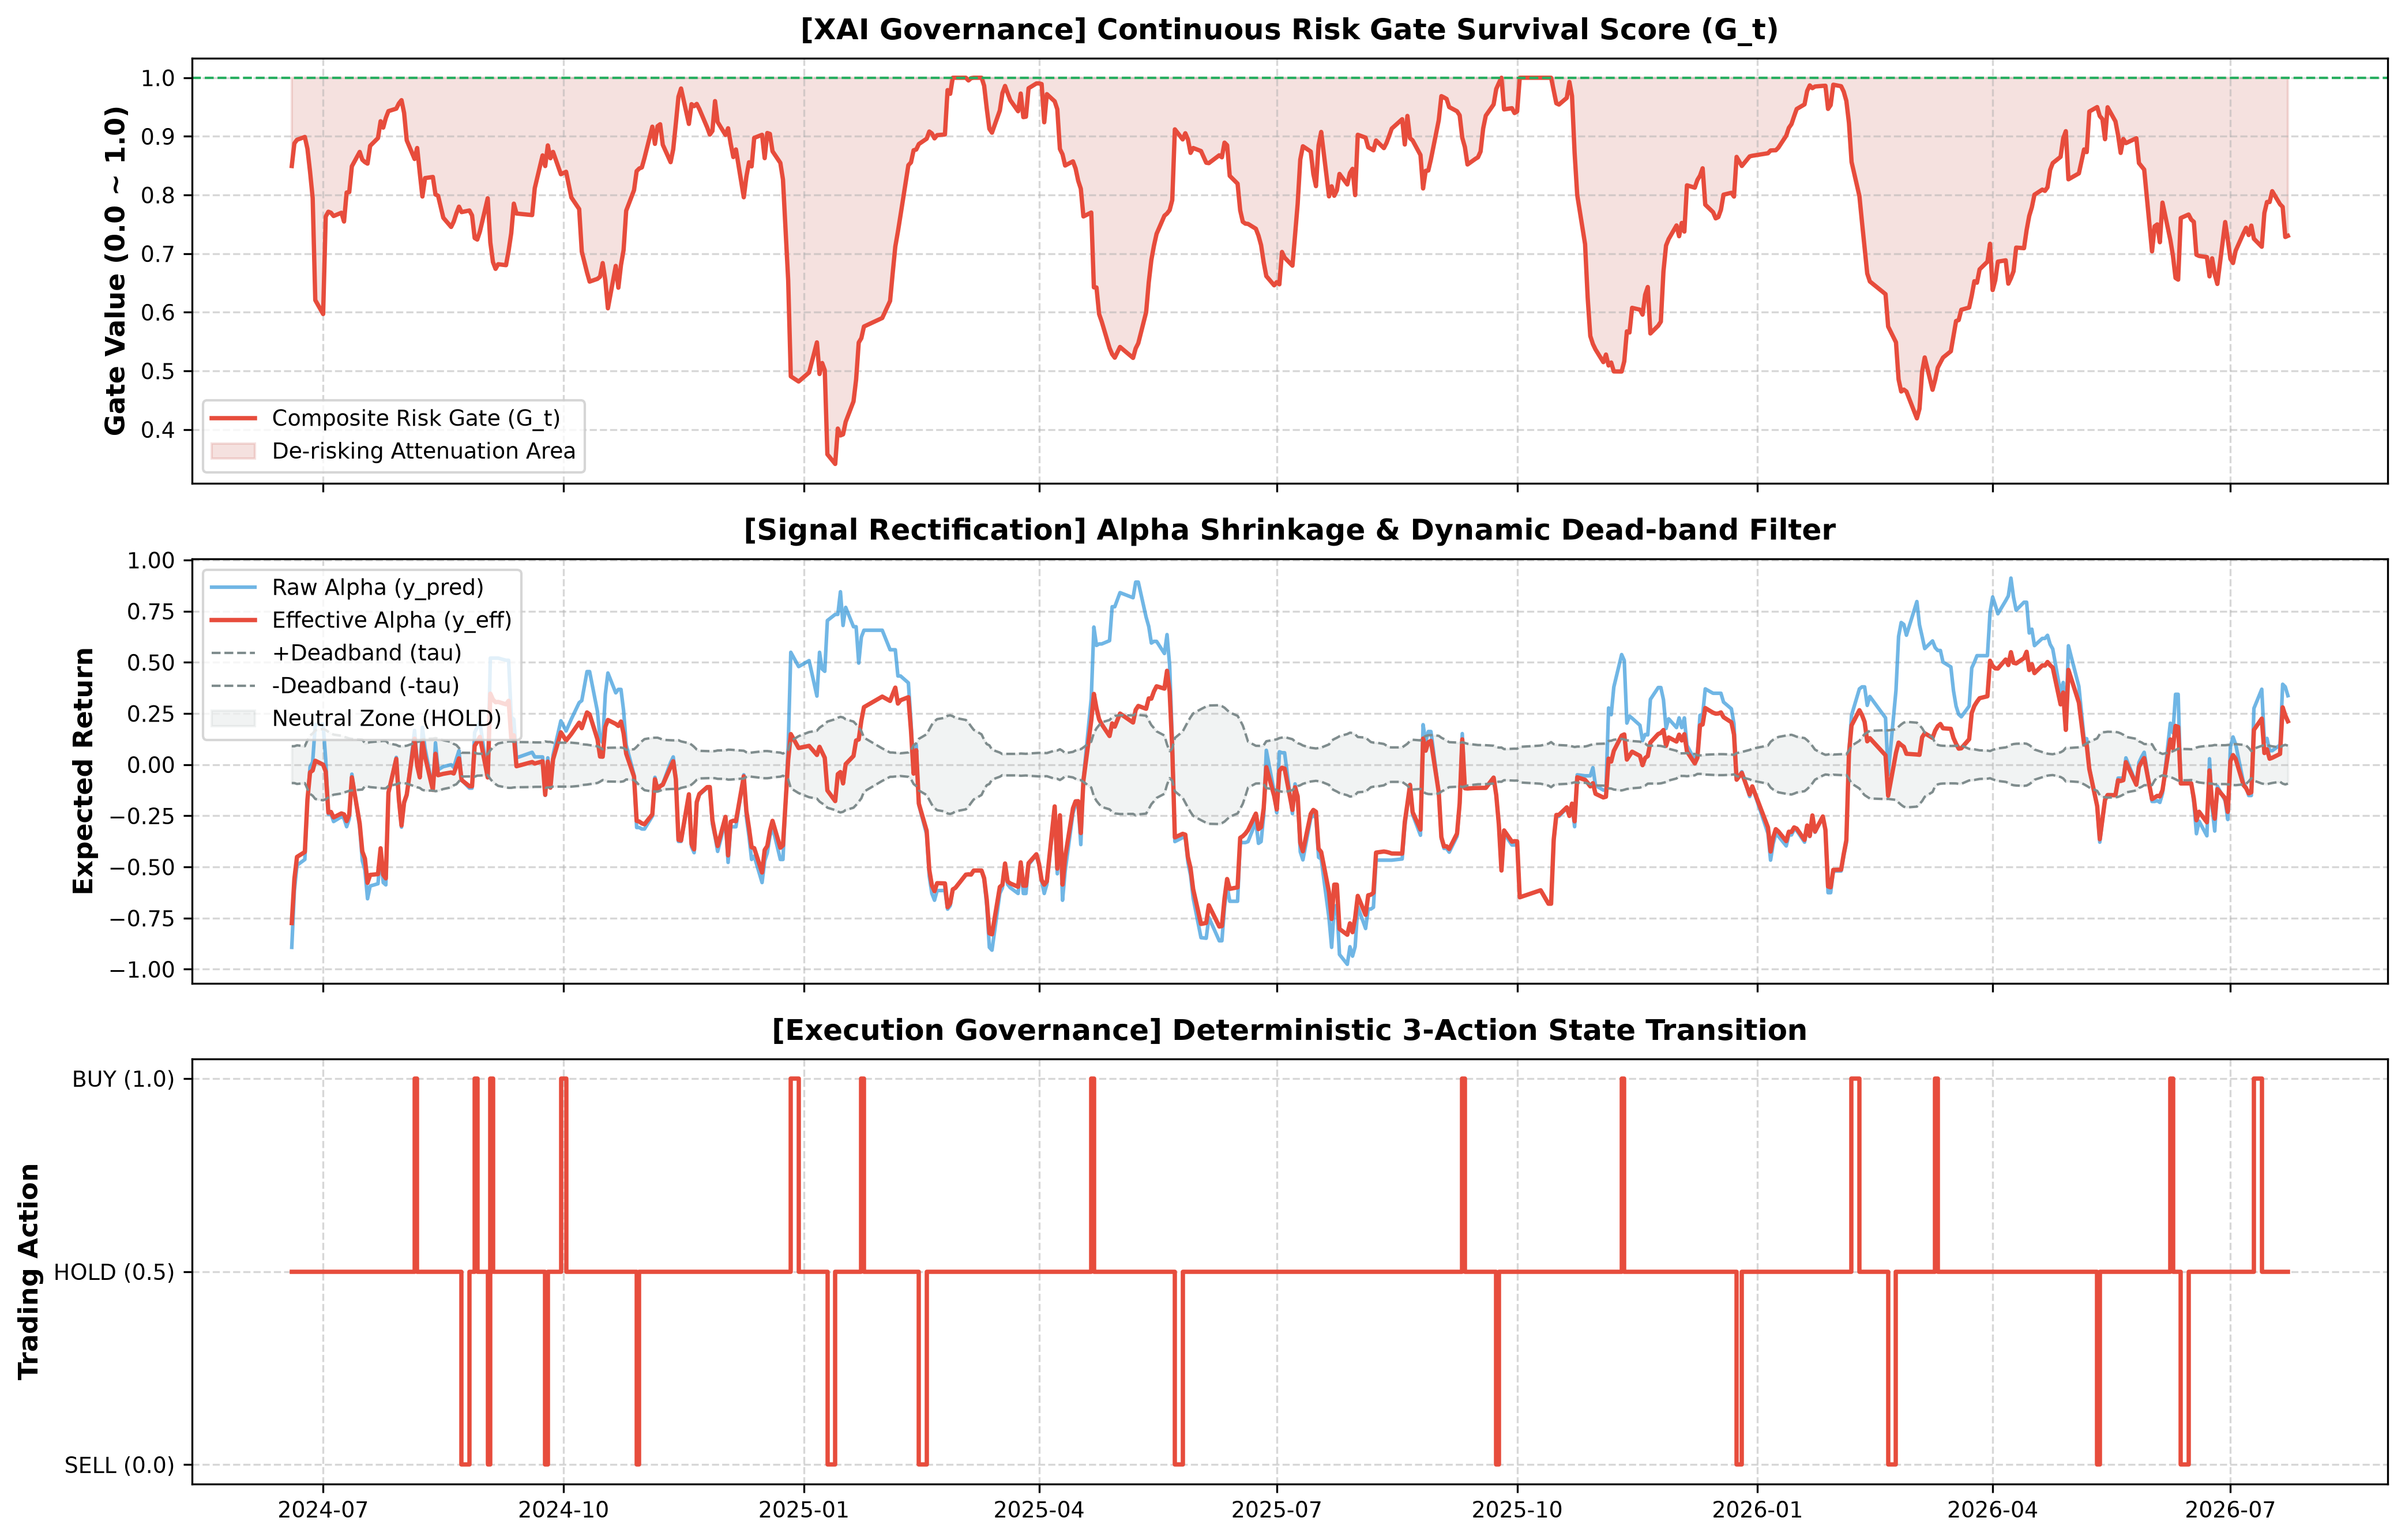

In [7]:
# [셀 3] XAI 의사결정 거버넌스 거동 3단 진단 시각화
import matplotlib.pyplot as plt
from src.test.backtest.visualizer import plot_gating_behavior_diagnostics

fig_gating, axes_gating = plot_gating_behavior_diagnostics(
    signals_xai_gated, composite_risk_gate
)
plt.show()

In [8]:
# [셀 4] 포트폴리오 시뮬레이션
from src.test.backtest.simulation_engine import run_ablation_simulation

# KOSPI 가격을 수동으로 넘기지 않고, 내부 benchmark_provider가 action_index를 기반으로 자체 수집 및 정산
simulation_ledgers, simulation_summary_table = run_ablation_simulation(
    raw_model_actions=signals_raw_model["action"],
    xai_gated_actions=signals_xai_gated["action"],
)

display(simulation_summary_table)

,Strategy 0 (Benchmark),Strategy 1 (Raw Model),Strategy 2 (XAI-Gated)
Portfolio Accounting Audit,,,
Final NAV,2.5339,2.0997,2.1106
Cumulative Return (%),+153.39%,+109.97%,+111.06%
Max Drawdown (MDD %),-28.51%,-22.11%,-14.73%
Total Turnover (x),1.00x,23.00x,25.00x
Transaction Cost (%),-0.12%,-2.88%,-3.12%
Market Exposure Ratio (%),100.0%,46.6%,37.3%
Executed Trades (BUY / SELL),1회 / 0회,12회 / 11회,13회 / 12회


In [9]:
# [셀 5] 3대 전략 계량 성과 지표 및 Newey-West 통계 감사표 사출
from src.test.backtest.performance_metrics import evaluate_ablation_performance

ablation_audit_summary_table = evaluate_ablation_performance(simulation_ledgers)
display(ablation_audit_summary_table)

,Strategy 0 (Benchmark),Strategy 1 (Raw Model),Strategy 2 (XAI-Gated),XAI Delta (vs Raw)
Ablation Audit Metric,,,,
Total Return (%),153.390000,109.97000,111.060000,+1.09%p
CAGR (%),58.460000,44.38000,44.750000,+0.37%p
Annualized Vol (%),36.160000,27.16000,21.640000,-5.52%p
Downside Deviation (%),25.640000,18.18000,13.390000,-4.79%p
Sharpe Ratio,1.456000,1.48900,1.818000,+0.329
Sortino Ratio,2.054000,2.22500,2.938000,+0.713
Maximum Drawdown (%),28.510000,22.11000,14.730000,-7.38%p (방어)
Calmar Ratio,2.051000,2.00700,3.038000,+1.031
Annual Turnover (x),0.500000,11.39000,12.380000,+0.99x


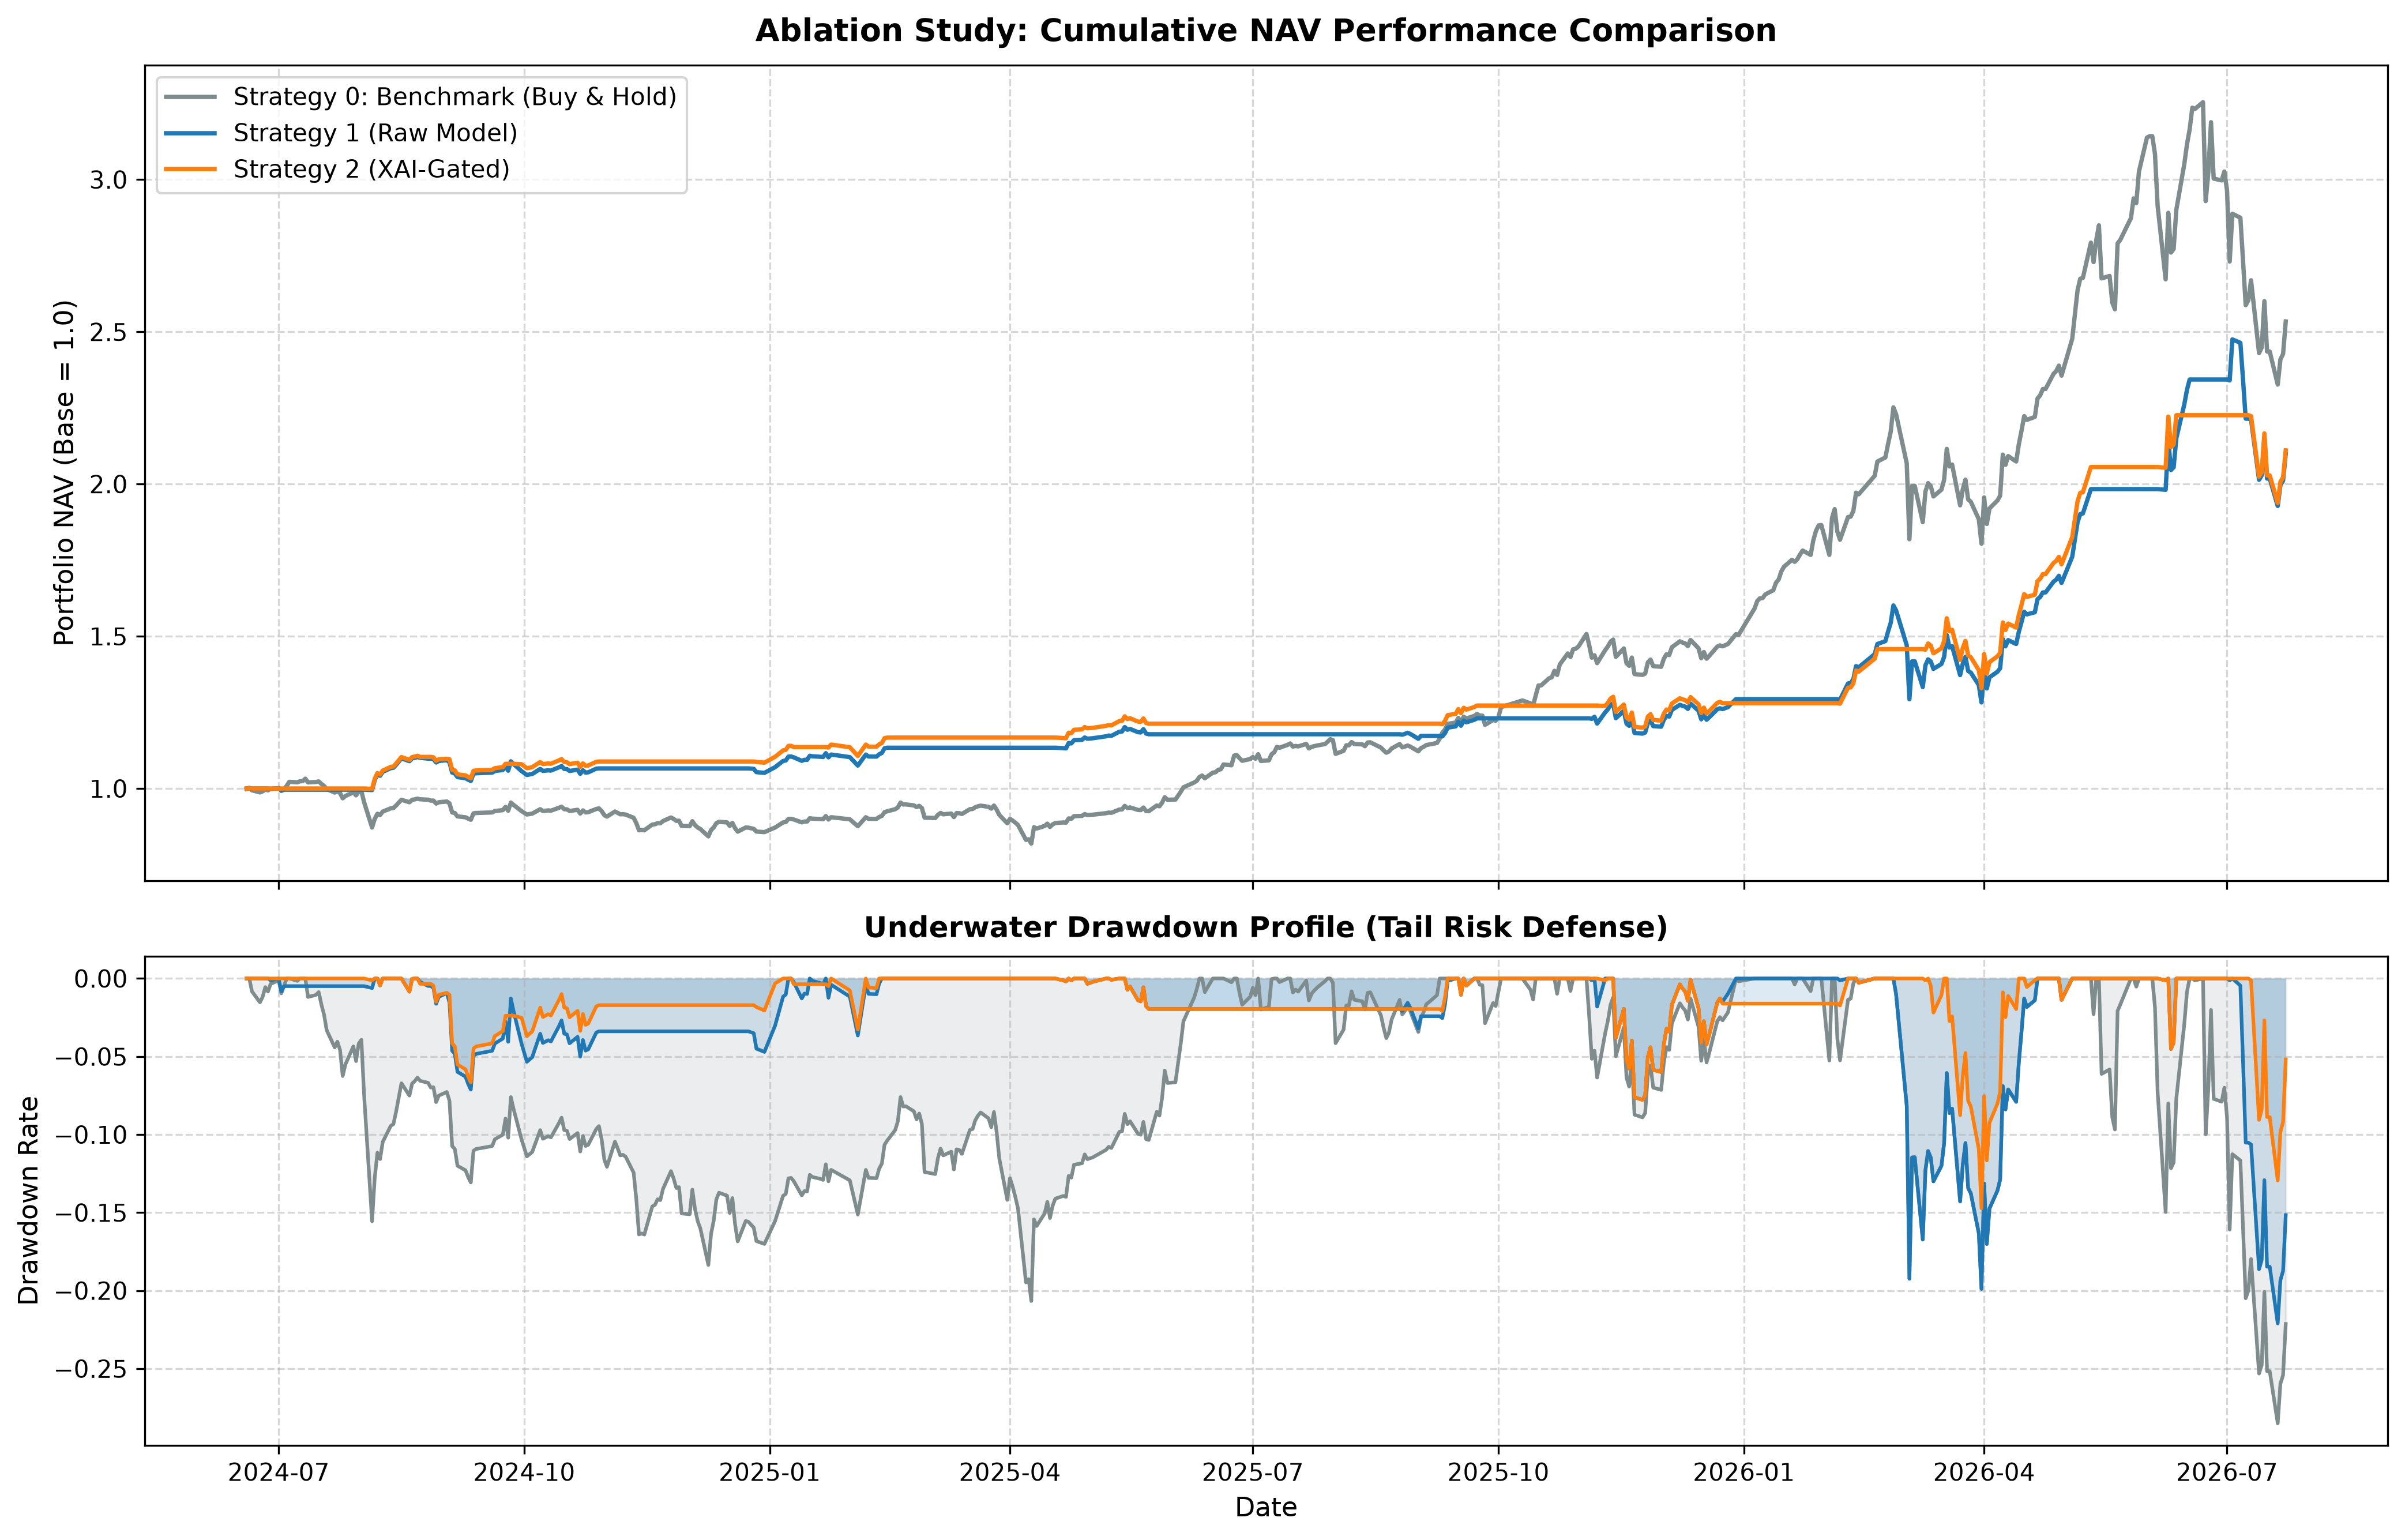

In [10]:
# [셀 6] 3대 전략 누적 성과 곡선(NAV) 및 드로다운(Underwater) 시각화
import matplotlib.pyplot as plt
from src.test.backtest.visualizer import plot_ablation_performance

fig_ablation, axes_ablation = plot_ablation_performance(simulation_ledgers)
plt.show()

In [11]:
# ==============================================================================
# [셀 7] 백테스트 거버넌스 및 성과 다차원 아티팩트 일괄 배포 집행
# ==============================================================================
from src.test.backtest.backtest_deployer import deploy_backtest_artifacts

# 1. 시계열 신호 및 복합 게이트 통합 데이터 바인딩
strategy_signals = pd.DataFrame(
    {
        "prediction_raw": test_predictions["prediction"],
        "action_raw": signals_raw_model["action"],
        "position_raw": signals_raw_model["position"],
        "action_gated": signals_xai_gated["action"],
        "position_gated": signals_xai_gated["position"],
        "dynamic_deadband": signals_xai_gated["dynamic_deadband"],
        "composite_risk_gate": composite_risk_gate,
    },
    index=test_features_and_target.index,
)

risk_gates_data = {
    "composite_risk_gate": composite_risk_gate,
    "individual_gates": individual_gates,
    "risk_distances": risk_distances,
}

# 2. 6대 계량 및 거버넌스 정량 감사 보고서 바인딩
backtest_reports = {
    "gate_summary": dashboards["gate_summary"],
    "regime_attribution": dashboards["regime_attribution"],
    "factor_audit_trail": dashboards["factor_audit_trail"],
    "execution_governance_audit": action_summary_table,
    "portfolio_accounting_summary": simulation_summary_table,
    "ablation_performance_metrics": ablation_audit_summary_table,
}

# 3. 고해상도 시각화 플롯 바인딩
backtest_figures = {
    "gating_behavior_diagnostics": fig_gating,
    "ablation_equity_drawdown": fig_ablation,
}

# 4. 전체 감사 추적용 매니페스트 메타데이터 구성
manifest_metadata = {
    "backtest_run_date": "2026-10-06 04:08:00",
    "evaluation_period": {
        "start": str(test_features_and_target.index.min().date()),
        "end": str(test_features_and_target.index.max().date()),
        "trading_days": len(test_features_and_target),
        "cv_trading_days": 203,
        "holding_period": 20,
    },
    "champion_model_source": "artifacts/models/champion_regressor.joblib",
    "benchmark": "KOSPI",
    "transaction_cost_bps": 25.0,
    "deadband_tau": 0.11170,
    "performance_summary": {
        "strategy_0_benchmark": {
            "total_return": 153.39,
            "cagr": 58.46,
            "sharpe": 1.456,
            "mdd": -28.51,
        },
        "strategy_1_raw_model": {
            "total_return": 109.97,
            "cagr": 44.38,
            "sharpe": 1.489,
            "mdd": -22.11,
        },
        "strategy_2_xai_gated": {
            "total_return": 111.06,
            "cagr": 44.75,
            "sharpe": 1.818,
            "sortino": 2.938,
            "calmar": 3.038,
            "mdd": -14.73,
            "newey_west_t": 2.478,
            "newey_west_p": 0.0135,
        },
    },
}

# 5. 일괄 배포 파이프라인 호출
deployed_backtest_paths = deploy_backtest_artifacts(
    governance_config=governance_config,
    risk_gates_data=risk_gates_data,
    strategy_signals=strategy_signals,
    simulation_ledgers=simulation_ledgers,
    reports=backtest_reports,
    figures=backtest_figures,
    manifest_metadata=manifest_metadata,
    artifact_root="artifacts/backtest",
)

print("[배포 완료] 적재된 백테스트 아티팩트 계층 디렉터리:")
for layer_name, directory_path in deployed_backtest_paths.items():
    print(f" - {layer_name:20s}: {directory_path}")

[배포 완료] 적재된 백테스트 아티팩트 계층 디렉터리:
 - config              : artifacts/backtest/config
 - data                : artifacts/backtest/data
 - reports             : artifacts/backtest/reports
 - figures             : artifacts/backtest/figures
